In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

print("Ambiente de análise configurado!")

Ambiente de análise configurado!


In [2]:
import sqlite3

# Conectando ao banco de dados
conexao = sqlite3.connect("gta.db")

print("Conexão com o banco GTA VI realizada com sucesso!")

Conexão com o banco GTA VI realizada com sucesso!


In [3]:
import pandas as pd

consulta = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

tabelas = pd.read_sql_query(consulta, conexao)

display(tabelas)

,name
0,gta6_dataset


In [4]:
for tabela in tabelas["name"]:
    print(f"\nTabela: {tabela}")

    estrutura = pd.read_sql_query(
        f"PRAGMA table_info('{tabela}')",
        conexao
    )

    display(estrutura)


Tabela: gta6_dataset


,cid,name,type,notnull,dflt_value,pk
0,0,frame_id,TEXT,0,None,0
1,1,trailer_number,INTEGER,0,None,0
2,2,frame_number,INTEGER,0,None,0
3,3,timestamp,TEXT,0,None,0
4,4,image_filename,TEXT,0,None,0
5,5,scene_type,TEXT,0,None,0
6,6,location_name,TEXT,0,None,0
7,7,environment,TEXT,0,None,0
8,8,time_of_day,TEXT,0,None,0
9,9,weather,TEXT,0,None,0


In [5]:
for tabela in tabelas["name"]:
    print(f"\nPrimeiros registros de: {tabela}")

    dados = pd.read_sql_query(
        f'SELECT * FROM "{tabela}" LIMIT 5',
        conexao
    )

    display(dados)


Primeiros registros de: gta6_dataset


,frame_id,trailer_number,frame_number,timestamp,image_filename,scene_type,location_name,environment,time_of_day,weather,...,character_count,vehicles_present,vehicle_count,animals_present,animal_count,weapons_visible,objects_present,primary_action,image_caption,keywords
0,F00001,1,30,00:00.017,frame_00001.jpg,Marina,Bridge,Outdoor,Afternoon,Storm,...,3,NaN,0,NaN,0,Pistol,Palm Tree; Boat Dock; Street Lamp; Traffic Lig...,Driving,Driving scene in marina featuring Jason.,"marina, driving, jason, gang_member, npc_male"
1,F00002,2,60,00:00.034,frame_00002.jpg,Swamp,Vice Beach,Outdoor,Morning,Storm,...,1,NaN,0,Bird; Alligator,2,NaN,Palm Tree; Boat Dock; Billboard; Street Lamp,Shooting,Shooting scene in swamp featuring Gang Member.,"swamp, shooting, gang_member"
2,F00003,2,90,00:01.051,frame_00003.jpg,Club,Airport,Outdoor,Evening,Cloudy,...,3,Helicopter,1,NaN,0,NaN,Boat Dock; Building; Palm Tree,Walking,Walking scene in club featuring NPC Male.,"club, walking, npc_male, tourist, police"
3,F00004,2,120,00:01.068,frame_00004.jpg,Forest,Vice Beach,Indoor,Morning,Rainy,...,2,Truck,1,Dog,1,NaN,Traffic Light; Billboard; Street Lamp,Swimming,Swimming scene in forest featuring Lucia.,"forest, swimming, lucia, tourist"
4,F00005,2,150,00:01.085,frame_00005.jpg,Marina,Mall,Outdoor,Evening,Cloudy,...,2,Truck; Motorbike,2,NaN,0,NaN,Traffic Light; Building; Boat Dock; Bench; Str...,Flying,Flying scene in marina featuring Jason.,"marina, flying, jason, lucia"


In [6]:
df = pd.read_sql_query(
    "SELECT * FROM gta6_dataset",
    conexao
)

print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

Quantidade de linhas: 10000
Quantidade de colunas: 22


In [7]:
valores_ausentes = pd.DataFrame({
    "Valores ausentes": df.isnull().sum(),
    "Porcentagem (%)": (df.isnull().mean() * 100).round(2)
})

display(valores_ausentes.sort_values(
    by="Porcentagem (%)",
    ascending=False
))

,Valores ausentes,Porcentagem (%)
weapons_visible,6180,61.8
animals_present,4060,40.6
vehicles_present,3300,33.0
frame_number,0,0.0
frame_id,0,0.0
trailer_number,0,0.0
scene_type,0,0.0
image_filename,0,0.0
timestamp,0,0.0
location_name,0,0.0


In [8]:
print("Registros duplicados completos:", df.duplicated().sum())

print("Frame IDs duplicados:", df["frame_id"].duplicated().sum())

Registros duplicados completos: 9500
Frame IDs duplicados: 9500


In [9]:
distribuicao = df["trailer_number"].value_counts().sort_index()

display(distribuicao)

trailer_number
1    4900
2    5100
Name: count, dtype: int64

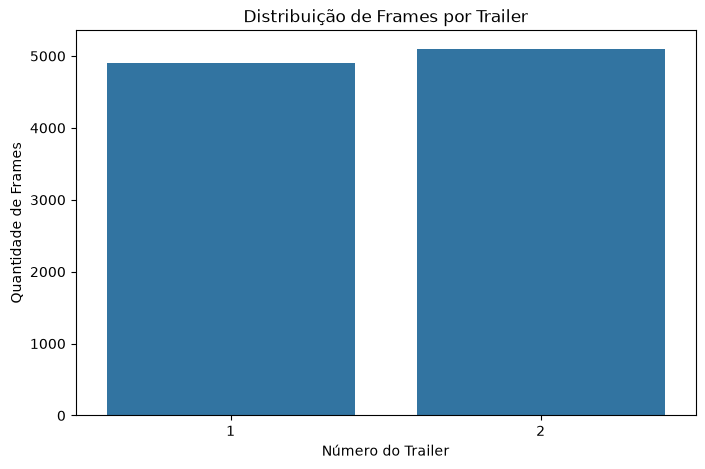

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="trailer_number"
)

plt.title("Distribuição de Frames por Trailer")
plt.xlabel("Número do Trailer")
plt.ylabel("Quantidade de Frames")

plt.show()

In [11]:
colunas = [
    "animals_present",
    "vehicles_present",
    "weapons_visible"
]

for coluna in colunas:
    print(f"\n--- {coluna} ---")
    print("Valores ausentes:", df[coluna].isna().sum())
    print("Valores preenchidos:", df[coluna].notna().sum())


--- animals_present ---
Valores ausentes: 4060
Valores preenchidos: 5940

--- vehicles_present ---
Valores ausentes: 3300
Valores preenchidos: 6700

--- weapons_visible ---
Valores ausentes: 6180
Valores preenchidos: 3820


In [12]:
print("ANIMAIS")
display(pd.crosstab(
    df["animals_present"].isna(),
    df["animal_count"],
    normalize="index"
).round(3) * 100)

print("VEÍCULOS")
display(pd.crosstab(
    df["vehicles_present"].isna(),
    df["vehicle_count"],
    normalize="index"
).round(3) * 100)

ANIMAIS


animal_count,0,1,2
animals_present,,,
False,0.0,50.5,49.5
True,100.0,0.0,0.0


VEÍCULOS


vehicle_count,0,1,2
vehicles_present,,,
False,0.0,51.6,48.4
True,100.0,0.0,0.0


In [13]:
display(
    df[df["weapons_visible"].isna()][
        ["frame_id", "trailer_number", "scene_type",
         "location_name", "weapons_visible"]
    ].head(10)
)

,frame_id,trailer_number,scene_type,location_name,weapons_visible
1,F00002,2,Swamp,Vice Beach,NaN
2,F00003,2,Club,Airport,NaN
3,F00004,2,Forest,Vice Beach,NaN
4,F00005,2,Marina,Mall,NaN
5,F00006,1,Airport,Ocean Drive,NaN
8,F00009,1,Club,Ocean Drive,NaN
9,F00010,2,Airport,Nightclub,NaN
10,F00011,1,Club,Nightclub,NaN
12,F00013,2,Marina,Vice Beach,NaN
16,F00017,1,Forest,Suburbs,NaN


In [14]:
display(
    df[df["weapons_visible"].notna()][
        ["frame_id", "trailer_number", "scene_type",
         "location_name", "weapons_visible"]
    ].head(10)
)

,frame_id,trailer_number,scene_type,location_name,weapons_visible
0,F00001,1,Marina,Bridge,Pistol
6,F00007,2,Marina,Harbor,Shotgun
7,F00008,2,Marina,Bridge,Pistol
11,F00012,1,Club,Downtown,Rifle
13,F00014,2,Highway,Airport,Rifle
14,F00015,1,Downtown,Bridge,Pistol
15,F00016,1,Forest,Airport,Shotgun
17,F00018,2,Downtown,Downtown,Rifle
18,F00019,2,Beach,Nightclub,Rifle
19,F00020,2,Club,Airport,Shotgun


In [3]:
import pandas as pd
import sqlite3

conexao = sqlite3.connect("gta.db")

df = pd.read_sql_query(
    "SELECT * FROM gta6_dataset",
    conexao
)

print(df.shape)

(10000, 22)


In [4]:
pd.crosstab(
    df["trailer_number"],
    df["weapons_visible"].isna()
)

weapons_visible,False,True
trailer_number,,
1,1740,3160
2,2080,3020


In [5]:
pd.crosstab(
    df["scene_type"],
    df["weapons_visible"].isna()
)

weapons_visible,False,True
scene_type,,
Airport,400,660
Beach,340,580
City,420,640
Club,560,540
Downtown,340,720
Forest,440,620
Highway,280,600
House,300,500
Marina,400,660


In [6]:
df["weapons_visible"].value_counts(dropna=True)

weapons_visible
Rifle      1120
Shotgun    1040
Knife       900
Pistol      760
Name: count, dtype: int64

In [7]:
print(df["weapons_visible"].unique())
print(df["weapons_visible"].isna().sum())

<StringArray>
['Pistol', nan, 'Shotgun', 'Rifle', 'Knife']
Length: 5, dtype: str
6180


In [8]:
df.dtypes

frame_id                str
trailer_number        int64
frame_number          int64
timestamp               str
image_filename          str
scene_type              str
location_name           str
environment             str
time_of_day             str
weather                 str
lighting_condition      str
characters_present      str
character_count       int64
vehicles_present        str
vehicle_count         int64
animals_present         str
animal_count          int64
weapons_visible         str
objects_present         str
primary_action          str
image_caption           str
keywords                str
dtype: object

In [12]:
from scipy.stats import chi2_contingency

tabela = pd.crosstab(df["scene_type"], df["weapons_visible"].isna())
chi2, p, gl, esperado = chi2_contingency(tabela)
print(f"chi2={chi2:.2f}, p-valor={p:.4f}")

chi2=121.55, p-valor=0.0000


In [13]:
df.groupby(df["weapons_visible"].isna()).mean(numeric_only=True).T

weapons_visible,False,True
trailer_number,1.544503,1.488673
frame_number,7098.534031,7772.427184
character_count,1.984293,1.964401
vehicle_count,0.900524,1.051780
animal_count,0.853403,0.909385


In [14]:
import numpy as np
v = np.sqrt(chi2 / (len(df) * (min(tabela.shape) - 1)))
print(f"V de Cramér = {v:.3f}")

V de Cramér = 0.110


In [15]:
termos = "gun|rifle|pistol|shotgun|knife|weapon|shoot|firearm|armed"
colunas_texto = ["objects_present", "primary_action", "image_caption", "keywords"]

for col in colunas_texto:
    menciona = df[col].str.contains(termos, case=False, na=False)
    print(f"--- {col} ---")
    print(pd.crosstab(
        menciona,
        df["weapons_visible"].isna(),
        rownames=["menciona arma"],
        colnames=["weapons NULL"]
    ))

--- objects_present ---
weapons NULL   False  True 
menciona arma              
False           3820   6180
--- primary_action ---
weapons NULL   False  True 
menciona arma              
False           3380   5480
True             440    700
--- image_caption ---
weapons NULL   False  True 
menciona arma              
False           3380   5480
True             440    700
--- keywords ---
weapons NULL   False  True 
menciona arma              
False           3380   5480
True             440    700


In [16]:
mask = df["primary_action"].str.contains(termos, case=False, na=False)

# 1) as três colunas casam nos mesmos registros?
for col in ["image_caption", "keywords"]:
    print(col, (mask == df[col].str.contains(termos, case=False, na=False)).all())

# 2) quais termos aparecem
print(df.loc[mask, "primary_action"].str.extract(f"(?i)({termos})")[0].str.lower().value_counts())

# 3) exemplos de NULL que mencionam arma
df.loc[mask & df["weapons_visible"].isna(),
       ["primary_action", "image_caption", "keywords"]].head(10)

image_caption True
keywords True
0
shoot    1140
Name: count, dtype: int64


,primary_action,image_caption,keywords
1,Shooting,Shooting scene in swamp featuring Gang Member.,"swamp, shooting, gang_member"
32,Shooting,Shooting scene in forest featuring NPC Female.,"forest, shooting, npc_female, lucia"
44,Shooting,Shooting scene in airport featuring NPC Male.,"airport, shooting, npc_male"
64,Shooting,Shooting scene in marina featuring Gang Member.,"marina, shooting, gang_member"
79,Shooting,Shooting scene in beach featuring Gang Member.,"beach, shooting, gang_member"
88,Shooting,Shooting scene in swamp featuring NPC Female.,"swamp, shooting, npc_female, npc_male, gang_me..."
89,Shooting,Shooting scene in swamp featuring Jason.,"swamp, shooting, jason, npc_male"
92,Shooting,Shooting scene in city featuring NPC Male.,"city, shooting, npc_male, gang_member"
95,Shooting,Shooting scene in club featuring NPC Female.,"club, shooting, npc_female, lucia"
109,Shooting,Shooting scene in downtown featuring Lucia.,"downtown, shooting, lucia, police"


In [17]:
# 1) Outras ações também têm padrão de NULL?
pd.crosstab(df["primary_action"], df["weapons_visible"].isna(), margins=True)

# 2) Tiro com arma que não atira? (ex.: Knife em cena de Shooting)
pd.crosstab(
    df.loc[mask, "weapons_visible"].fillna("NULL"),
    "registros"
)

col_0,registros
weapons_visible,
Knife,120
NULL,700
Pistol,120
Rifle,80
Shotgun,120


In [19]:
df_tratado = df.copy()

df_tratado["animals_present"] = df_tratado["animals_present"].fillna("Nenhum")
df_tratado["vehicles_present"] = df_tratado["vehicles_present"].fillna("Nenhum")

print(df_tratado[["animals_present", "vehicles_present"]].isna().sum())

animals_present     0
vehicles_present    0
dtype: int64


In [20]:
import numpy as np

df_tratado["weapons_info_status"] = np.where(
    df["weapons_visible"].isna(), "Não informado", "Informado"
)

df_tratado["tiro_sem_arma_registrada"] = (
    (df["primary_action"] == "Shooting") & df["weapons_visible"].isna()
)

df_tratado["weapons_visible"] = df["weapons_visible"].fillna("Não informado")

print(df_tratado["weapons_info_status"].value_counts())
print(df_tratado["tiro_sem_arma_registrada"].sum())  # esperado: 700

weapons_info_status
Não informado    6180
Informado        3820
Name: count, dtype: int64
700


In [21]:
df_tratado.to_sql("gta6_tratado", conexao, if_exists="replace", index=False)

10000

In [22]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].to_frame("nulos")
nulos["%"] = (nulos["nulos"] / len(df) * 100).round(1)
print(nulos.sort_values("nulos", ascending=False))

                  nulos     %
weapons_visible    6180  61.8
animals_present    4060  40.6
vehicles_present   3300  33.0


In [23]:
# NULL deveria ter contagem 0; preenchido deveria ter contagem > 0
print(pd.crosstab(df["animals_present"].isna(), df["animal_count"] == 0,
                  rownames=["animals NULL"], colnames=["animal_count == 0"]))

print(pd.crosstab(df["vehicles_present"].isna(), df["vehicle_count"] == 0,
                  rownames=["vehicles NULL"], colnames=["vehicle_count == 0"]))

animal_count == 0  False  True 
animals NULL                   
False               5940      0
True                   0   4060
vehicle_count == 0  False  True 
vehicles NULL                   
False                6700      0
True                    0   3300


In [24]:
print(df["frame_id"].duplicated().sum())
print(df["image_filename"].duplicated().sum())
print(df.duplicated().sum())

9500
9500
9500


In [25]:
print(df.drop_duplicates().shape)  # esperado: (500, 22)
print(df.value_counts().describe())  # quantas vezes cada registro se repete

(500, 22)
count    69.0
mean     20.0
std       0.0
min      20.0
25%      20.0
50%      20.0
75%      20.0
max      20.0
Name: count, dtype: float64


In [26]:
df_unico = df.drop_duplicates().reset_index(drop=True)
print(df_unico.shape)
print(df_unico["frame_id"].is_unique)  # esperado: True

df_unico.to_sql("gta6_unico", conexao, if_exists="replace", index=False)

(500, 22)
True


500

In [27]:
from scipy.stats import chi2_contingency
import numpy as np

print(df_unico["weapons_visible"].isna().value_counts())

tabela = pd.crosstab(df_unico["scene_type"], df_unico["weapons_visible"].isna())
print(tabela)
chi2, p, gl, esperado = chi2_contingency(tabela)
v = np.sqrt(chi2 / (len(df_unico) * (min(tabela.shape) - 1)))
print(f"chi2={chi2:.2f}, p={p:.4f}, V={v:.3f}")

mask = df_unico["primary_action"] == "Shooting"
print(pd.crosstab(mask, df_unico["weapons_visible"].isna(),
                  rownames=["Shooting"], colnames=["weapons NULL"]))

weapons_visible
True     309
False    191
Name: count, dtype: int64
weapons_visible  False  True 
scene_type                   
Airport             20     33
Beach               17     29
City                21     32
Club                28     27
Downtown            17     36
Forest              22     31
Highway             14     30
House               15     25
Marina              20     33
Swamp               17     33
chi2=6.08, p=0.7322, V=0.110
weapons NULL  False  True 
Shooting                  
False           169    274
True             22     35


In [28]:
df_final = df_unico.copy()

# Animais e veículos: NULL = contagem zero (validado)
df_final["animals_present"] = df_final["animals_present"].fillna("Nenhum")
df_final["vehicles_present"] = df_final["vehicles_present"].fillna("Nenhum")

# Armas: NULL = não registrado
df_final["weapons_info_status"] = np.where(
    df_unico["weapons_visible"].isna(), "Não informado", "Informado"
)
df_final["tiro_sem_arma_registrada"] = (
    (df_unico["primary_action"] == "Shooting") & df_unico["weapons_visible"].isna()
)
df_final["weapons_visible"] = df_unico["weapons_visible"].fillna("Não informado")

print(df_final.shape)                                    # (500, 24)
print(df_final["weapons_info_status"].value_counts())    # 309 / 191
print(df_final["tiro_sem_arma_registrada"].sum())        # 35
print(df_final.isna().sum().sum())                       # 0

df_final.to_sql("gta6_final", conexao, if_exists="replace", index=False)

(500, 24)
weapons_info_status
Não informado    309
Informado        191
Name: count, dtype: int64
35
0


500

In [29]:
print(df_final["trailer_number"].value_counts())
print(df_unico["weapons_visible"].value_counts())   # frequência das armas (sem NULL)

trailer_number
2    255
1    245
Name: count, dtype: int64
weapons_visible
Rifle      56
Shotgun    52
Knife      45
Pistol     38
Name: count, dtype: int64


In [30]:
from scipy.stats import chisquare
print(chisquare(df_unico["weapons_visible"].value_counts()))

Power_divergenceResult(statistic=np.float64(3.9528795811518322), pvalue=np.float64(0.26659744407807))


In [31]:
for col in ["scene_type", "environment", "time_of_day", "weather", "lighting_condition", "primary_action"]:
    print(f"--- {col} ---")
    print(df_final[col].value_counts())
    print()

--- scene_type ---
scene_type
Club        55
Marina      53
Forest      53
Airport     53
Downtown    53
City        53
Swamp       50
Beach       46
Highway     44
House       40
Name: count, dtype: int64

--- environment ---
environment
Indoor     251
Outdoor    249
Name: count, dtype: int64

--- time_of_day ---
time_of_day
Afternoon    137
Night        132
Morning      118
Evening      113
Name: count, dtype: int64

--- weather ---
weather
Cloudy    105
Storm     101
Foggy      99
Rainy      98
Sunny      97
Name: count, dtype: int64

--- lighting_condition ---
lighting_condition
Shadow       135
Bright       130
Low Light    125
Neon         110
Name: count, dtype: int64

--- primary_action ---
primary_action
Walking     77
Driving     68
Running     67
Talking     66
Dancing     62
Swimming    59
Shooting    57
Flying      44
Name: count, dtype: int64



In [32]:
df_final["n_listados"] = df_final["characters_present"].str.split(",").str.len()
print(pd.crosstab(df_final["character_count"], df_final["n_listados"]))

n_listados         1
character_count     
1                168
2                178
3                154


In [33]:
print(pd.crosstab(df_final["environment"], df_final["scene_type"]))
print(pd.crosstab(df_final["time_of_day"], df_final["lighting_condition"]))

scene_type   Airport  Beach  City  Club  Downtown  Forest  Highway  House  \
environment                                                                 
Indoor            25     25    23    34        25      31       21     16   
Outdoor           28     21    30    21        28      22       23     24   

scene_type   Marina  Swamp  
environment                 
Indoor           26     25  
Outdoor          27     25  
lighting_condition  Bright  Low Light  Neon  Shadow
time_of_day                                        
Afternoon               43         34    24      36
Evening                 32         26    28      27
Morning                 26         28    25      39
Night                   29         37    33      33


In [34]:
print(df_final["characters_present"].value_counts().head(15))
print(df_final[["character_count", "characters_present"]].head(10))

characters_present
NPC Female              29
NPC Male                28
Gang Member             26
Lucia                   25
Police                  23
Jason                   19
Tourist                 18
Lucia; Tourist           8
Lucia; NPC Female        7
Jason; Police            7
NPC Male; Lucia          7
Lucia; Jason             7
Tourist; NPC Female      7
Police; NPC Male         7
NPC Male; NPC Female     6
Name: count, dtype: int64
   character_count                 characters_present
0                3       Jason; Gang Member; NPC Male
1                1                        Gang Member
2                3          NPC Male; Tourist; Police
3                2                     Lucia; Tourist
4                2                       Jason; Lucia
5                3         NPC Female; Jason; Tourist
6                2                  Lucia; NPC Female
7                1                              Jason
8                3  NPC Male; NPC Female; Gang Member
9         

In [35]:
# 1) Confirmar as associações (ou a falta delas)
for a, b in [("environment", "scene_type"), ("time_of_day", "lighting_condition")]:
    t = pd.crosstab(df_final[a], df_final[b])
    chi2, p, gl, esp = chi2_contingency(t)
    v = np.sqrt(chi2 / (len(df_final) * (min(t.shape) - 1)))
    print(f"{a} x {b}: chi2={chi2:.2f}, p={p:.3f}, V={v:.3f}")

# 2) A legenda é coerente com a cena?
cena_na_legenda = df_final.apply(
    lambda r: r["scene_type"].lower() in r["image_caption"].lower(), axis=1
)
print(cena_na_legenda.value_counts())

# 3) Colunas que ficaram truncadas
for col in ["weather", "lighting_condition", "primary_action"]:
    print(f"--- {col} ---")
    print(df_final[col].value_counts())

environment x scene_type: chi2=7.91, p=0.543, V=0.126
time_of_day x lighting_condition: chi2=8.49, p=0.485, V=0.075
True    500
Name: count, dtype: int64
--- weather ---
weather
Cloudy    105
Storm     101
Foggy      99
Rainy      98
Sunny      97
Name: count, dtype: int64
--- lighting_condition ---
lighting_condition
Shadow       135
Bright       130
Low Light    125
Neon         110
Name: count, dtype: int64
--- primary_action ---
primary_action
Walking     77
Driving     68
Running     67
Talking     66
Dancing     62
Swimming    59
Shooting    57
Flying      44
Name: count, dtype: int64


In [36]:
df_final["n_listados"] = df_final["characters_present"].str.split(";").str.len()
print(pd.crosstab(df_final["character_count"], df_final["n_listados"]))
print((df_final["character_count"] == df_final["n_listados"]).all())

n_listados         1    2    3
character_count               
1                168    0    0
2                  0  178    0
3                  0    0  154
True


In [37]:
# Lista completa de ações
print(df_final["primary_action"].value_counts().to_string())

# 1) Dirigindo sem veículo?
print(pd.crosstab(df_final["primary_action"], df_final["vehicle_count"] == 0,
                  rownames=["ação"], colnames=["sem veículo"]))

# 2) Ação x cena (nadando na rodovia? voando no clube?)
print(pd.crosstab(df_final["primary_action"], df_final["scene_type"]))

# 3) Clima x horário e clima x ambiente (sol à noite? tempestade dentro de casa?)
print(pd.crosstab(df_final["weather"], df_final["time_of_day"]))
print(pd.crosstab(df_final["weather"], df_final["environment"]))

primary_action
Walking     77
Driving     68
Running     67
Talking     66
Dancing     62
Swimming    59
Shooting    57
Flying      44
sem veículo  False  True 
ação                     
Dancing         42     20
Driving         44     24
Flying          32     12
Running         41     26
Shooting        38     19
Swimming        43     16
Talking         46     20
Walking         49     28
scene_type      Airport  Beach  City  Club  Downtown  Forest  Highway  House  \
primary_action                                                                 
Dancing               6      3     9     8         7       6        4      4   
Driving               5      3     9    10        11       8        7      3   
Flying                4      5     4     6         4       0        3      5   
Running               7     11     4     4         7       9       12      4   
Shooting              8      2     4     5         4       8        1      9   
Swimming              3      9     7     8   

In [1]:
import pandas as pd
import sqlite3

conexao = sqlite3.connect("gta.db")

df = pd.read_sql_query(
    "SELECT * FROM gta6_dataset",
    conexao
)

print(df.shape)

(10000, 22)


In [5]:
import pandas as pd
import sqlite3
import numpy as np

conexao = sqlite3.connect("gta.db")

df_final = pd.read_sql_query(
    "SELECT * FROM gta6_final",
    conexao
)

print(df_final.shape)

(500, 24)


In [6]:
print(df_final.shape)

(500, 24)


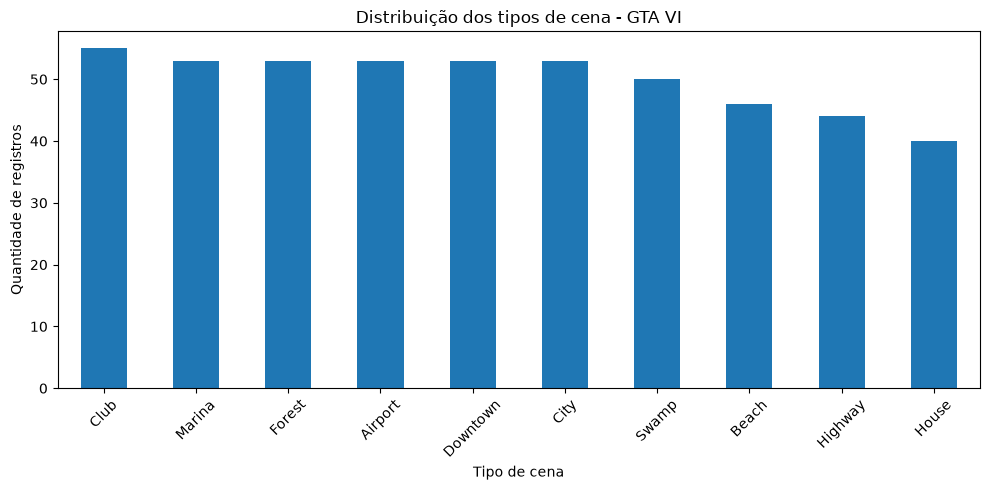

In [7]:
import matplotlib.pyplot as plt

df_final["scene_type"].value_counts().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribuição dos tipos de cena - GTA VI")
plt.xlabel("Tipo de cena")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
print(df_final["scene_type"].value_counts())

scene_type
Club        55
Marina      53
Forest      53
Airport     53
Downtown    53
City        53
Swamp       50
Beach       46
Highway     44
House       40
Name: count, dtype: int64


In [10]:
df_final = pd.read_sql_query("SELECT * FROM gta6_final", conexao)
print(df_final.shape)  # tem que dar (500, 24)

df_final["dirigindo_sem_veiculo"] = (
    (df_final["primary_action"] == "Driving") & (df_final["vehicle_count"] == 0)
)

print("=== Categorias ===")
for col in ["scene_type", "primary_action", "weather", "lighting_condition", "time_of_day"]:
    print(f"\n{col}\n{df_final[col].value_counts().to_string()}")

print("\n=== Personagens ===")
print(df_final["characters_present"].str.split(";").explode().str.strip().value_counts().to_string())

print("\n=== Top 10 keywords ===")
print(df_final["keywords"].str.split(",").explode().str.strip().value_counts().head(10).to_string())

print("\n=== Contagens (media) ===")
print(df_final[["character_count", "vehicle_count", "animal_count"]].mean().round(2).to_string())

print("\n=== Inconsistências ===")
print("Tiro sem arma:", df_final["tiro_sem_arma_registrada"].sum())
print("Direção sem veículo:", df_final["dirigindo_sem_veiculo"].sum())

(500, 24)
=== Categorias ===

scene_type
scene_type
Club        55
Marina      53
Forest      53
Airport     53
Downtown    53
City        53
Swamp       50
Beach       46
Highway     44
House       40

primary_action
primary_action
Walking     77
Driving     68
Running     67
Talking     66
Dancing     62
Swimming    59
Shooting    57
Flying      44

weather
weather
Cloudy    105
Storm     101
Foggy      99
Rainy      98
Sunny      97

lighting_condition
lighting_condition
Shadow       135
Bright       130
Low Light    125
Neon         110

time_of_day
time_of_day
Afternoon    137
Night        132
Morning      118
Evening      113

=== Personagens ===
characters_present
Lucia          152
NPC Female     148
Police         142
Gang Member    137
NPC Male       136
Tourist        136
Jason          135

=== Top 10 keywords ===
keywords
lucia          152
npc_female     148
police         142
gang_member    137
npc_male       136
tourist        136
jason          135
walking         77
d

In [11]:
print("=== Personagens ===")
print(df_final["characters_present"].str.split(";").explode().str.strip().value_counts().to_string())

print("\n=== Top 10 keywords ===")
print(df_final["keywords"].str.split(",").explode().str.strip().value_counts().head(10).to_string())

=== Personagens ===
characters_present
Lucia          152
NPC Female     148
Police         142
Gang Member    137
NPC Male       136
Tourist        136
Jason          135

=== Top 10 keywords ===
keywords
lucia          152
npc_female     148
police         142
gang_member    137
npc_male       136
tourist        136
jason          135
walking         77
driving         68
running         67
